# Detector de gorras con YOLO11

**Trabajo Práctico 2 — Visión por Computadora** · Aprendizaje Automático II
**Fecha de entrega:** 13/11/2026

| Rol | Integrante | Mail | Responsabilidad |
|---|---|---|---|
| 1 | Mauricio Chocholacek | mauricio.chocholacek@istea.com.ar | Roboflow: revisión de recuadros, partición, aumentación y exportación |
| 2 | Paola Lucia Pierolivo Fernandez | paola.pierolivo@istea.com.ar | Criterio de anotación, estadísticas y línea de base |
| 3 | Veronica Andrea Gonzalez | veronica.gonzalez@istea.com.ar | Configuración A y comparación A vs. B |
| 4 | Daiana Marilyn Ruiz Díaz | daiana.ruiz@istea.com.ar | Configuración B y fotos "in the wild" |
| 5 | Andrea Romeo | andrea.romeo@istea.com.ar | Inferencia sobre test y análisis de errores |
| 6 | Rodolfo Javier Berrone | rodolfo.berrone@istea.com.ar | Notebook final, introducción y conclusiones |

**Objetivo:** enseñarle a YOLO11 a detectar **gorras con visera**, una clase que no está en COCO, con *fine-tuning* de `yolo11n.pt` sobre 64 fotos propias anotadas en Roboflow.

**Cómo correrlo:** todo lo necesario está en el repo (dataset, fotos de prueba y código). No hace falta Roboflow, Drive ni ninguna API key.
1. `git clone https://github.com/javi2481/detector-gorras-yolo11.git` y `pip install -r requirements.txt`.
2. Abrir `notebooks/TP2_Detector_Gorras.ipynb` y *Reiniciar y ejecutar todo*.
3. Por defecto usa los pesos ya entrenados de `modelos/` y tarda unos minutos, incluso en CPU. Para reentrenar desde cero, poner `ENTRENAR = True` (≈ 12 min con GPU, varias horas en CPU).

## 0. Preparación del entorno

In [1]:
# Dependencias del repo (requirements.txt en la raíz)
%pip install -q ultralytics==8.4.210 pandas matplotlib pyyaml pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\Equipo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import os, shutil, time, glob
from pathlib import Path
import cv2
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image, ImageOps
from IPython.display import Image as IPyImage, display
from ultralytics import YOLO

SEED = 42                        # misma semilla en todas las corridas
CONF = 0.25                      # confianza mínima para aceptar una detección
# False: usa los pesos ya entrenados de modelos/ (minutos, incluso en CPU).
# True: reentrena A y B desde cero (≈ 12 min con GPU, varias horas en CPU).
ENTRENAR = False
# Raíz del repo: el notebook vive en notebooks/, así que subimos un nivel
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (RAIZ / "datos").is_dir():
    # Fuera del repo (por ejemplo, en Colab): clonamos el repo para tener dataset y fotos
    import subprocess
    subprocess.run(["git", "clone", "-q", "https://github.com/javi2481/detector-gorras-yolo11.git"], check=True)
    RAIZ = Path.cwd() / "detector-gorras-yolo11"
DATOS = RAIZ / "datos"
RUNS = str(RAIZ / "runs" / "detect")   # todas las corridas de Ultralytics se guardan acá, con nombre fijo
pd.set_option("display.max_colwidth", None)

**Mapa de progreso.** Al inicio de cada fase mostramos en qué etapa del proyecto estamos: verde, terminada; amarillo, la actual; gris, pendiente. Debajo de cada etapa terminada va su resultado principal.

In [3]:
ETAPAS = ["Dataset", "Línea de base", "Fine-tuning A/B", "Elegir ganador", "Test + in the wild"]
resultados_etapas = {}   # cada fase agrega acá su resultado principal

# Texto de cada caja, partido en dos líneas para que entre cómodo
ETIQUETAS = {"Dataset": "Dataset", "Línea de base": "Línea\nde base",
             "Fine-tuning A/B": "Fine-tuning\nA / B", "Elegir ganador": "Elegir\nganador",
             "Test + in the wild": "Test +\nin the wild"}

def mostrar_progreso(etapa_actual):
    # Posición de la etapa actual; si no está en la lista ("Fin"), todas quedan terminadas
    actual = ETAPAS.index(etapa_actual) if etapa_actual in ETAPAS else len(ETAPAS)

    fig, ax = plt.subplots(figsize=(15, 2.2))
    for i, etapa in enumerate(ETAPAS):
        # Verde: terminada | amarillo: actual | gris: pendiente
        if i < actual:
            color, texto = "#b7e1b5", ETIQUETAS[etapa] + " ✓"
        elif i == actual:
            color, texto = "#ffe08a", ETIQUETAS[etapa]
        else:
            color, texto = "#e6e6e6", ETIQUETAS[etapa]

        x = i * 3   # cada caja ocupa 2.4 de ancho y deja 0.6 para la flecha
        ax.add_patch(plt.Rectangle((x, 0), 2.4, 1, facecolor=color, edgecolor="gray"))
        ax.text(x + 1.2, 0.5, texto, ha="center", va="center", fontsize=11, weight="bold")
        ax.text(x + 1.2, -0.35, resultados_etapas.get(etapa, ""), ha="center", fontsize=9, color="dimgray")
        if i < len(ETAPAS) - 1:
            ax.annotate("", xy=(x + 3, 0.5), xytext=(x + 2.4, 0.5), arrowprops=dict(arrowstyle="->"))

    ax.set_xlim(-0.2, len(ETAPAS) * 3)
    ax.set_ylim(-0.7, 1.2)
    ax.axis("off")
    plt.show()

## 1. Fase 1 — Dataset y anotación

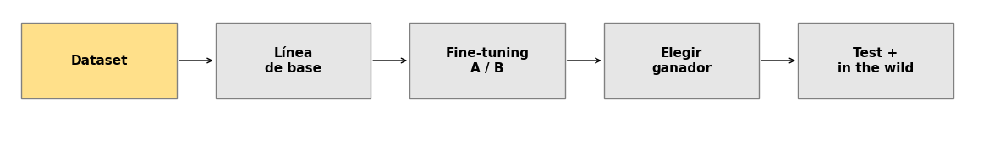

In [4]:
mostrar_progreso("Dataset")

### 1.1 Criterio de anotación

Qué cuenta como gorra y cómo se marca:

- Solo gorras **con visera**: no se marcan gorros de lana, sombreros ni viseras sueltas.
- Un recuadro por gorra, pegado al borde e incluyendo la visera.
- Se marcan gorras tapadas, cortadas por el borde o lejanas **si se ve la mayor parte y se reconocen sin dudas**.
- Se marcan desde cualquier ángulo. Si la gorra está puesta, el recuadro toma solo la gorra.

Al principio acordamos marcar solo gorras completas. Al revisar, mantuvimos las cortadas o tapadas que se reconocían bien, porque suman variedad de oclusión.

### 1.2 El dataset

Versión 2 del proyecto de Roboflow, exportada en formato YOLOv11. La exportación está guardada en `datos/dataset/` del repo, así que no hace falta descargarla.

In [5]:
data_dir = str(DATOS / "dataset")
assert os.path.isdir(data_dir), f"No se encuentra el dataset en {data_dir}"
print("Dataset en:", data_dir)

Dataset en: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\dataset


In [6]:
with open(os.path.join(data_dir, 'data.yaml')) as f:
    cfg = yaml.safe_load(f)

# Pasamos las rutas a absolutas y guardamos la copia en runs/, así no se modifica el data.yaml del repo
SPLITS = {'train': 'train', 'val': 'valid', 'test': 'test'}
for key, folder in SPLITS.items():
    ruta = os.path.join(data_dir, folder, 'images')
    if os.path.isdir(ruta):
        cfg[key] = ruta
    else:
        print(f'Atención: no existe la carpeta {folder}/images')
cfg.pop('path', None)

os.makedirs(RAIZ / 'runs', exist_ok=True)
DATA_YAML = str(RAIZ / 'runs' / 'data.yaml')
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

CLASES = cfg['names'] if isinstance(cfg['names'], list) else list(cfg['names'].values())
print('Clases:', CLASES, '| nc =', cfg['nc'])
if cfg['nc'] != 1:
    print('Atención: hay más de una clase. Unificarlas en "gorra" en Roboflow y generar otra versión.')

for folder in SPLITS.values():
    carpeta = os.path.join(data_dir, folder, 'images')
    n = len(os.listdir(carpeta)) if os.path.isdir(carpeta) else 0
    print(f'{folder:>5}: {n} imágenes')

print('\ndata.yaml listo en:', DATA_YAML)

Clases: ['Gorra'] | nc = 1
train: 180 imágenes
valid: 13 imágenes
 test: 6 imágenes

data.yaml listo en: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\data.yaml


### 1.3 Partición y aumentación

- **Partición:** 45 train / 13 valid / 6 test (≈ 70/20/10). Roboflow muestra 180 en train porque cuenta las copias aumentadas.
- **Preprocesamiento:** orientación automática y *resize* (estirado) a 640x640.

**Aumentaciones** (solo sobre train, 4 versiones por foto; valid y test quedan sin aumentar para evaluar con fotos reales):

| Aumentación | Por qué tiene sentido |
|---|---|
| Flip horizontal | Una gorra espejada sigue siendo una gorra |
| Flip vertical | En fotos desde arriba no hay "arriba" natural. Tiene un costo: también invierte gorras puestas, un caso irreal |
| Rotación ±18° | Cabezas inclinadas y fotos de celular torcidas |
| Ruido (1,92 % de píxeles) | Fotos de celular con poca luz o compresión |

### 1.4 Estadísticas del dataset

In [7]:
# Cantidad de fotos y de gorras marcadas en cada partición
for particion in ['train', 'valid', 'test']:
    carpeta = f'{data_dir}/{particion}/labels'
    archivos = os.listdir(carpeta)
    gorras = 0
    for archivo in archivos:
        with open(f'{carpeta}/{archivo}') as f:
            gorras += len(f.readlines())
    print(particion, '- fotos:', len(archivos), '- gorras marcadas:', gorras)

train - fotos: 180 - gorras marcadas: 200
valid - fotos: 13 - gorras marcadas: 15
test - fotos: 6 - gorras marcadas: 7


In [8]:
# Tamaño de cada gorra: qué porcentaje de la foto ocupa su recuadro
chicas, medianas, grandes = 0, 0, 0
for particion in ['train', 'valid', 'test']:
    carpeta = f'{data_dir}/{particion}/labels'
    for archivo in os.listdir(carpeta):
        with open(f'{carpeta}/{archivo}') as f:
            for linea in f.readlines():
                valores = linea.split()
                area = float(valores[3]) * float(valores[4]) * 100
                if area < 5:
                    chicas += 1
                elif area < 25:
                    medianas += 1
                else:
                    grandes += 1
total = chicas + medianas + grandes
print('Chicas (menos del 5% de la foto):', chicas, f'({chicas/total:.0%})')
print('Medianas (entre 5% y 25%):', medianas, f'({medianas/total:.0%})')
print('Grandes (más del 25%):', grandes, f'({grandes/total:.0%})')

Chicas (menos del 5% de la foto): 41 (18%)
Medianas (entre 5% y 25%): 112 (50%)
Grandes (más del 25%): 69 (31%)


| Partición | Fotos originales | Gorras | Fotos exportadas |
|---|---|---|---|
| Train | 45 | 50 | 180 |
| Valid | 13 | 15 | 13 |
| Test | 6 | 7 | 6 |
| **Total** | **64** | **72** | **199** |

**Tamaño de las gorras** (porcentaje de la foto que ocupa el recuadro): 18 % chicas (< 5 %), 50 % medianas y 31 % grandes (> 25 %). Las chicas son las fotos tomadas de lejos, y esperamos que sean las más difíciles. Los conteos incluyen las copias aumentadas, por eso se comparan porcentajes.

### 1.5 Ejemplos anotados y casos dudosos

In [9]:
# Buscamos fotos para comentar: varias gorras, gorras chicas o recuadros que tocan el borde
encontradas = set()
for particion in ['train', 'valid', 'test']:
    carpeta = f'{data_dir}/{particion}/labels'
    for archivo in sorted(os.listdir(carpeta)):
        with open(f'{carpeta}/{archivo}') as f:
            lineas = f.readlines()
        notas = []
        if len(lineas) > 1:
            notas.append(f'{len(lineas)} gorras')
        for linea in lineas:
            valores = linea.split()
            x, y = float(valores[1]), float(valores[2])
            ancho, alto = float(valores[3]), float(valores[4])
            if ancho * alto * 100 < 5:
                notas.append('gorra chica')
            if x - ancho/2 < 0.01 or x + ancho/2 > 0.99 or y - alto/2 < 0.01 or y + alto/2 > 0.99:
                notas.append('toca el borde')
        nombre = archivo.split('.rf.')[0]
        if notas and nombre not in encontradas:
            encontradas.add(nombre)
            print(particion, '-', nombre, '-', ', '.join(notas))

train - Gorra_10A_jpg - 2 gorras, gorra chica
train - Gorra_1A_jpg - 2 gorras
train - Gorra_2A_jpg - toca el borde
train - Gorra_3A_jpg - gorra chica
train - Gorra_4A_jpg - 2 gorras, gorra chica
train - gorra_10v_jpeg - 2 gorras, toca el borde
train - gorra_11m_jpeg - toca el borde
train - gorra_12m_png - 2 gorras, gorra chica, gorra chica
train - gorra_12p_jpeg - gorra chica
train - gorra_14p_jpeg - gorra chica
train - gorra_16p_jpeg - toca el borde
train - gorra_18p_jpeg - toca el borde
train - gorra_19v_jpeg - toca el borde
train - gorra_20v_jpeg - toca el borde
train - gorra_21v_jpeg - toca el borde
train - gorra_3p_jpeg - gorra chica
train - gorra_4v_jpeg - toca el borde
train - gorra_5p_jpeg - gorra chica
train - gorra_5v_jpeg - toca el borde
train - gorra_6m_jpeg - toca el borde
train - gorra_6p_jpeg - gorra chica
train - gorra_7m_jpeg - toca el borde
train - gorra_8m_jpeg - gorra chica
train - gorra_8v_jpeg - toca el borde
valid - gorra_10p_jpeg - toca el borde
valid - gorra_11

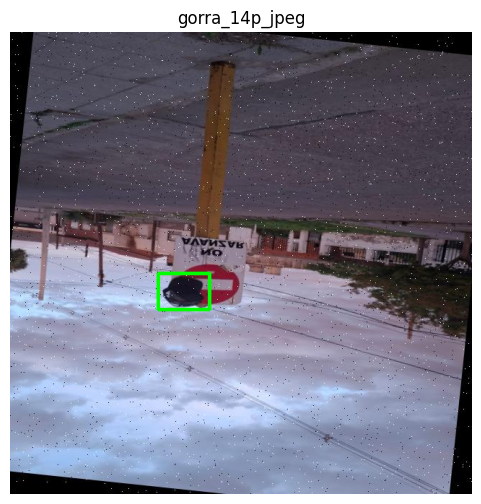

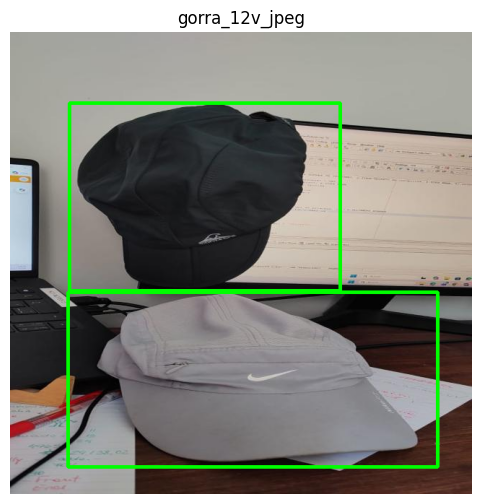

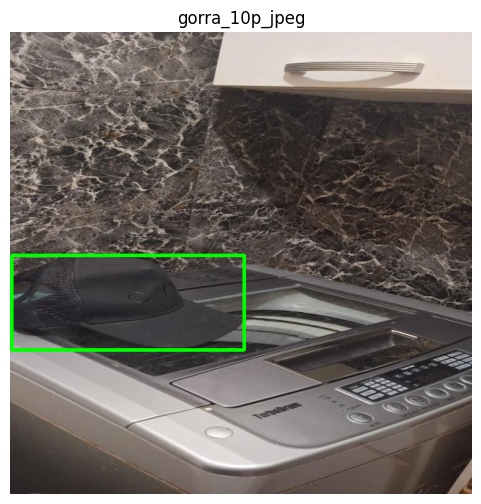

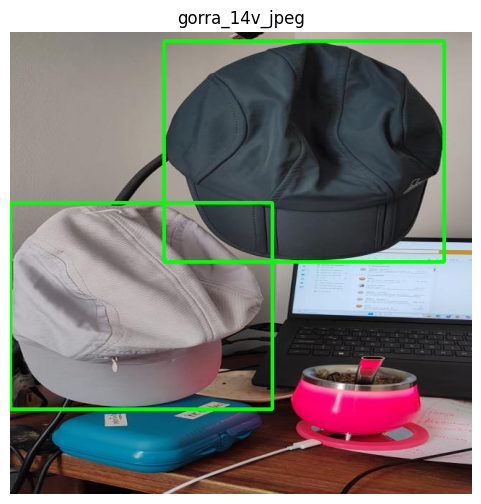

In [10]:
# Mostramos algunas fotos con los recuadros que marcamos en Roboflow
def mostrar_recuadros(particion, nombre):
    # Buscamos la foto por su nombre y armamos la ruta a su archivo de recuadros
    ruta_imagen = glob.glob(os.path.join(data_dir, particion, 'images', f'{nombre}*'))[0]
    ruta_label = Path(ruta_imagen).parent.parent / 'labels' / (Path(ruta_imagen).stem + '.txt')

    # Abrimos la foto y guardamos su tamaño en píxeles
    img = cv2.imread(ruta_imagen)
    alto_img, ancho_img = img.shape[:2]

    # Leemos cada recuadro (vienen como fracción de la foto) y lo pasamos a píxeles para dibujarlo
    with open(ruta_label) as f:
        for linea in f.readlines():
            valores = linea.split()
            x, y = float(valores[1]) * ancho_img, float(valores[2]) * alto_img
            ancho, alto = float(valores[3]) * ancho_img, float(valores[4]) * alto_img
            cv2.rectangle(img, (int(x - ancho/2), int(y - alto/2)), (int(x + ancho/2), int(y + alto/2)), (0, 255, 0), 3)

    # Mostramos la foto (OpenCV usa los colores en orden BGR, los pasamos a RGB)
    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(nombre)
    plt.axis('off')
    plt.show()

# Gorra lejos (chica)
mostrar_recuadros('train', 'gorra_14p_jpeg')
# Foto con dos gorras
mostrar_recuadros('valid', 'gorra_12v_jpeg')
# Recuadro que toca el borde de la foto
mostrar_recuadros('valid', 'gorra_10p_jpeg')
# Dos gorras y recuadro que toca el borde
mostrar_recuadros('test', 'gorra_14v_jpeg')

| Foto | Caso | Decisión |
|---|---|---|
| gorra_14p (train) | Gorra lejana, menos del 5 % de la foto | Se marca: se distingue con claridad. Aparece espejada, rotada y con ruido por la aumentación |
| gorra_12v (valid) | Dos gorras apiladas | Un recuadro por gorra, aunque se toquen |
| gorra_10p (valid) | Gorra cortada por el borde | Se marca: se ve la mayor parte |
| gorra_14v (test) | Una gorra tapada por otra | Se marcan las dos |

Los casos dudosos fueron siempre los mismos: gorras cortadas, tapadas o lejanas. Se decidió según cuánto de la gorra se veía.

### Fotos fuera del dataset

Las fotos de la línea base y las "in the wild" están en `datos/fotos_prueba/`. Las "in the wild" no forman parte de ninguna partición del dataset, así que el modelo nunca las ve durante el entrenamiento. Las 3 de la línea base se prueban solo con `yolo11n.pt` sin entrenar, antes del *fine-tuning*.

In [11]:
CARPETA_BASE = str(DATOS / "fotos_prueba" / "linea_base")
CARPETA_WILD = str(DATOS / "fotos_prueba" / "in_the_wild")
assert os.path.isdir(CARPETA_BASE), f"No se encuentra la carpeta: {CARPETA_BASE}"
assert os.path.isdir(CARPETA_WILD), f"No se encuentra la carpeta: {CARPETA_WILD}"

fotos_wild = sorted(glob.glob(f"{CARPETA_WILD}/*"))
print("Fotos línea base:", sorted(os.listdir(CARPETA_BASE)))
print("Fotos in the wild:", [Path(f).name for f in fotos_wild])

Fotos línea base: ['gorra_1p.jpeg', 'gorra_2p.jpeg', 'gorra_3p.jpeg']
Fotos in the wild: ['gorra_2d.jpeg', 'gorra_5d.jpeg', 'gorra_6d.jpeg']


## 2. Fase 2 — Línea de base: YOLO11 sin entrenar

Probamos `yolo11n.pt` tal como viene, entrenado en COCO, sobre 3 fotos con gorras.

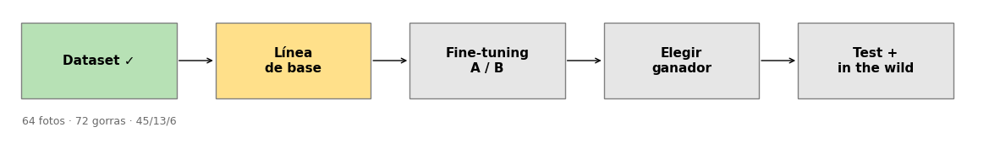

In [12]:
resultados_etapas["Dataset"] = "64 fotos · 72 gorras · 45/13/6"
mostrar_progreso("Línea de base")

In [13]:
YOLO("yolo11n.pt").predict(source=CARPETA_BASE, conf=CONF, save=True,
                           project=RUNS, name="baseline", exist_ok=True)

image 1/3 C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\fotos_prueba\linea_base\gorra_1p.jpeg: 320x640 1 bottle, 1 cup, 2 potted plants, 3 vases, 47.5ms


image 2/3 C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\fotos_prueba\linea_base\gorra_2p.jpeg: 640x320 1 bench, 1 chair, 42.0ms


image 3/3 C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\fotos_prueba\linea_base\gorra_3p.jpeg: 640x320 1 person, 30.8ms


Speed: 1.7ms preprocess, 40.1ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 320)


Results saved to C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect\baseline


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect/baseline\gorra_1p.jpg


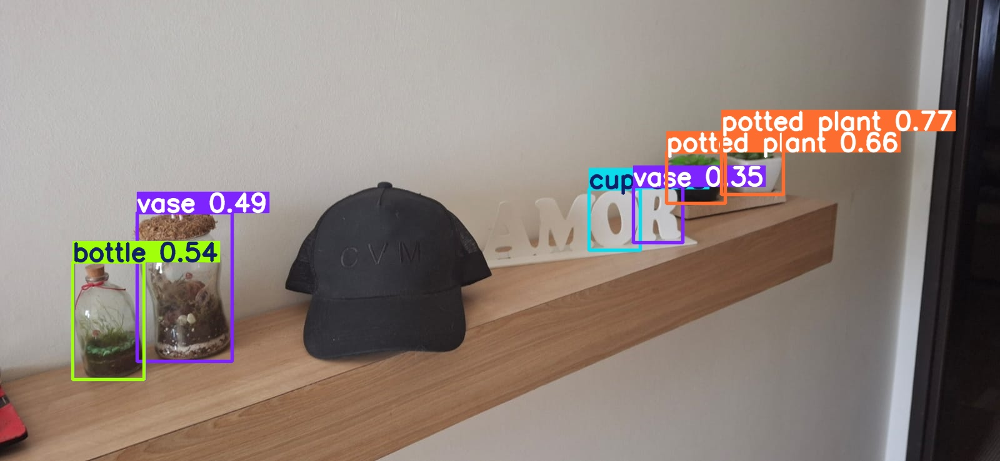

C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect/baseline\gorra_2p.jpg


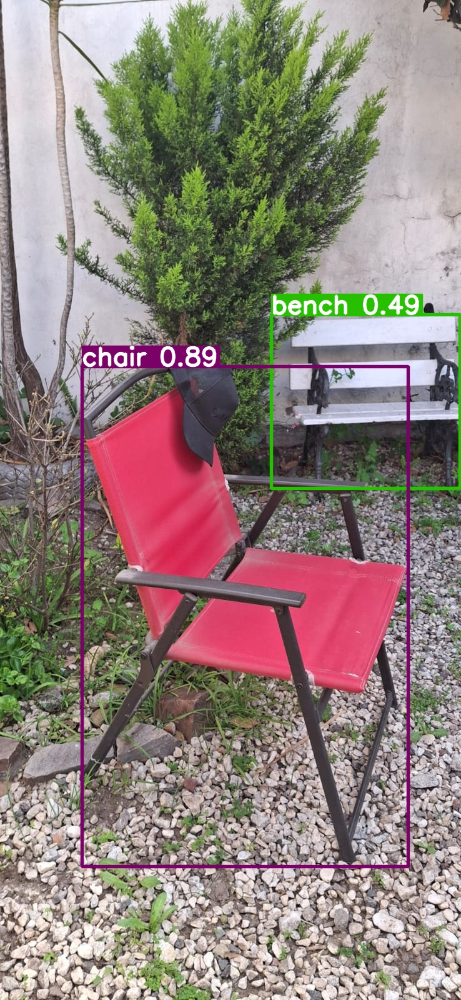

C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect/baseline\gorra_3p.jpg


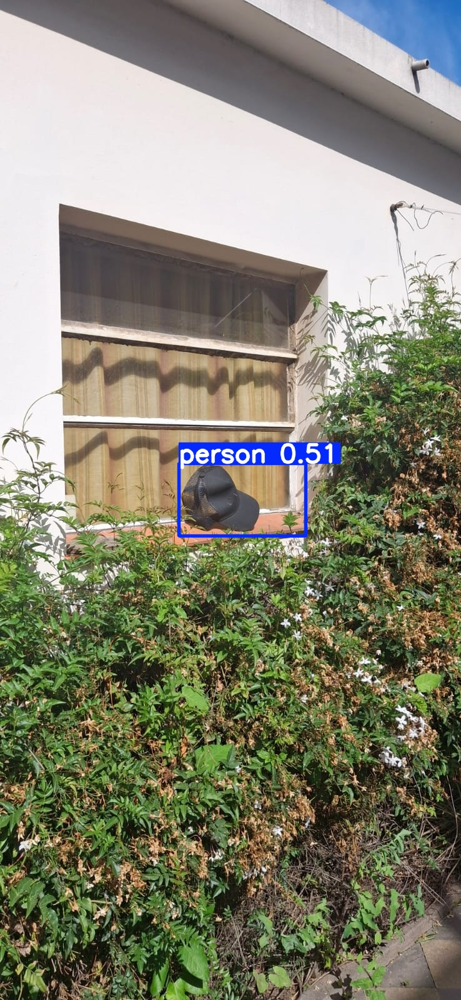

In [14]:
carpeta = f'{RUNS}/baseline'
for img in sorted(glob.glob(f'{carpeta}/*.jpg')):
    print(img)
    display(IPyImage(filename=img, width=600))

| Foto | Qué detectó | ¿Marcó la gorra? |
|---|---|---|
| gorra_1p (repisa) | bottle, cup, 2 potted plants, 3 vases | No |
| gorra_2p (silla en el jardín) | chair, bench | No: la incluyó dentro del recuadro de la silla |
| gorra_3p (ventana) | person (0.51) | Sí, pero como "person" |

El modelo detecta bien lo que rodea a la gorra (hasta 0.89 de confianza), pero a la gorra la ignora o la confunde con una persona, probablemente porque en COCO las gorras casi siempre aparecen puestas. **Hace falta el fine-tuning.**

## 3. Fase 3 — Fine-tuning de YOLO11

Partimos de pesos entrenados en COCO (**transferencia de aprendizaje**): con pocas fotos, es mucho mejor que entrenar desde cero. Comparamos dos configuraciones que difieren **en un solo factor**, el tamaño del modelo:

| | A | B |
|---|---|---|
| Modelo | `yolo11n` (2.6 M parámetros) | `yolo11s` (9.4 M parámetros) |
| Épocas · imgsz · seed | 100 · 640 · 42 | 100 · 640 · 42 |

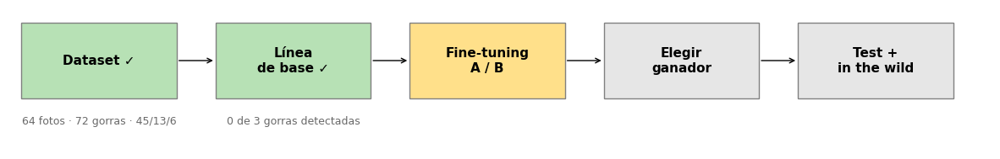

In [15]:
resultados_etapas["Línea de base"] = "0 de 3 gorras detectadas"   # sale de la tabla de la Fase 2
mostrar_progreso("Fine-tuning A/B")

### 3.1 Configuración A — `yolo11n`

In [16]:
# Configuración A
MODELO = "yolo11n.pt"
EPOCHS = 100
IMGSZ = 640
NOMBRE_CORRIDA = "train_A"

In [17]:
if ENTRENAR:
    model = YOLO(MODELO)

    inicio = time.time()
    resultados = model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        seed=SEED,
        plots=True,
        project=RUNS,
        name=NOMBRE_CORRIDA,
        exist_ok=True,      # si se vuelve a correr, pisa train_A en lugar de crear train_A-2
    )
    TIEMPO_A_MIN = (time.time() - inicio) / 60

    # Carpeta donde Ultralytics guardó esta corrida
    RUTA_A = Path(resultados.save_dir)
    print("Resultados guardados en:", RUTA_A)
    print(f"Tiempo de entrenamiento A: {TIEMPO_A_MIN:.1f} min")
else:
    # Pesos, curvas y results.csv de la corrida entregada (Colab, GPU T4)
    RUTA_A = RAIZ / "modelos" / "A"
    TIEMPO_A_MIN = 5.486   # minutos que tardó ese entrenamiento
    print("Usando el modelo ya entrenado en:", RUTA_A)

Usando el modelo ya entrenado en: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\modelos\A


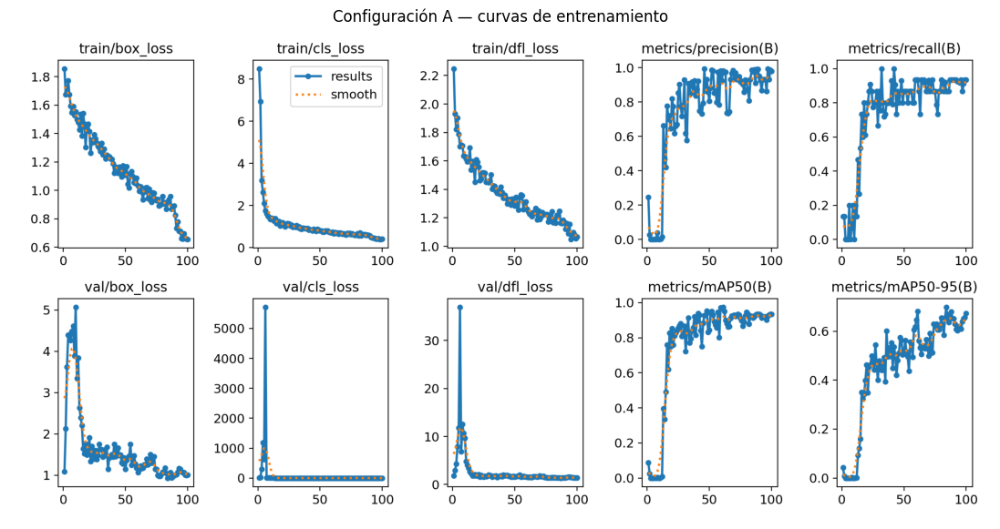

In [18]:
img = mpimg.imread(RUTA_A / "results.png")
plt.figure(figsize=(14, 7)); plt.imshow(img); plt.axis("off")
plt.title("Configuración A — curvas de entrenamiento"); plt.show()

**Cómo leer `results.png`**

| Gráfico | Qué mide |
|---|---|
| `box_loss` | Error en la posición y el tamaño del recuadro |
| `cls_loss` | Error al decidir si es gorra o no |
| `dfl_loss` | Ajuste fino de los bordes de la caja |
| `precision` | De lo detectado, cuánto era gorra: TP / (TP + FP) |
| `recall` | De las gorras reales, cuántas encontró: TP / (TP + FN) |
| `mAP50` | Calidad de detección, contando como acierto una caja con IoU ≥ 0.5 |
| `mAP50-95` | Lo mismo, pero exigiendo cajas cada vez más ajustadas |

Las pérdidas tienen que bajar y las métricas, subir. Validación tiene solo 15 gorras: cada una mueve el recall casi 7 puntos, por eso las curvas se ven "serruchadas".

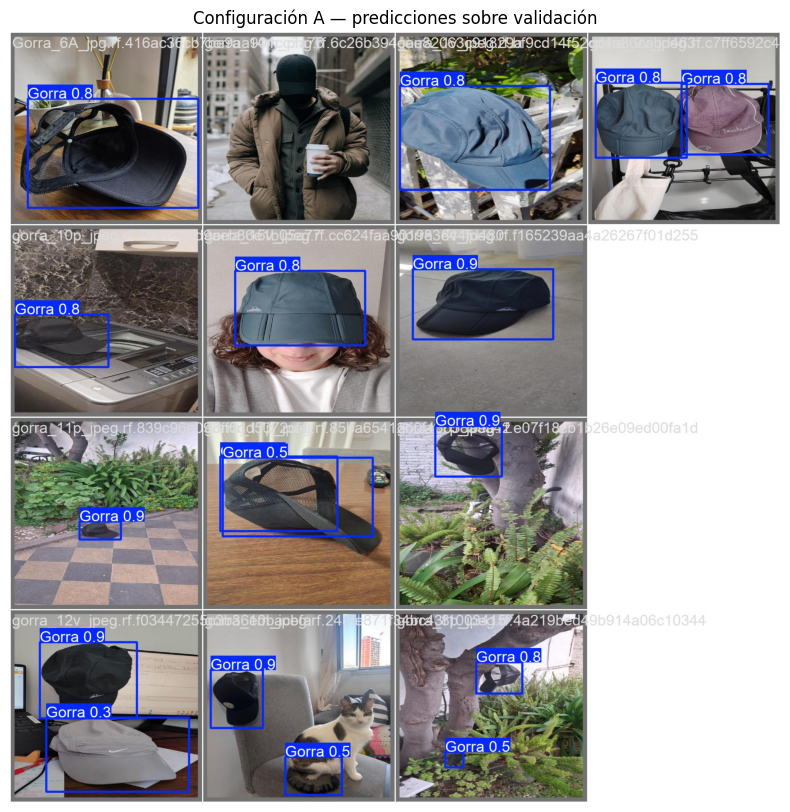

In [19]:
# Predicciones del modelo A sobre un lote de validación
img = mpimg.imread(RUTA_A / "val_batch0_pred.jpg")
plt.figure(figsize=(10, 10)); plt.imshow(img); plt.axis("off")
plt.title("Configuración A — predicciones sobre validación"); plt.show()

In [20]:
# Resumen numérico de las curvas de A (sale de results.csv, los mismos datos que results.png)
df_A = pd.read_csv(RUTA_A / "results.csv")
df_A.columns = [c.strip() for c in df_A.columns]

cols = ["epoch", "train/box_loss", "val/box_loss", "train/cls_loss", "val/cls_loss",
        "train/dfl_loss", "val/dfl_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
display(df_A[cols].iloc[[0, 9, 24, 49, 74, 89, 99]].round(3))   # épocas 1, 10, 25, 50, 75, 90, 100

for p in ["box", "cls", "dfl"]:
    ep_min = int(df_A.loc[df_A[f"val/{p}_loss"].idxmin(), "epoch"])
    print(f"val/{p}_loss: mínimo en la época {ep_min} "
          f"({df_A[f'val/{p}_loss'].min():.3f}) | en la época 100: {df_A[f'val/{p}_loss'].iloc[-1]:.3f}")

map50 = df_A["metrics/mAP50(B)"]
ep_estable = int(df_A.loc[(map50 >= 0.9 * map50.max()).idxmax(), "epoch"])
print(f"mAP@50 llega al 90 % de su máximo ({map50.max():.3f}) en la época {ep_estable}")

,epoch,train/box_loss,val/box_loss,train/cls_loss,val/cls_loss,train/dfl_loss,val/dfl_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,1.857,1.084,8.498,9.351,2.248,1.822,0.088,0.042
9,10,1.552,5.067,1.342,5.462,1.632,9.676,0.000,0.000
24,25,1.391,1.392,1.124,1.202,1.519,1.559,0.856,0.481
49,50,1.107,1.142,0.809,1.134,1.286,1.547,0.844,0.507
74,75,0.928,1.143,0.633,0.893,1.226,1.478,0.910,0.622
89,90,0.824,1.001,0.563,0.834,1.170,1.372,0.935,0.650
99,100,0.654,1.002,0.405,0.762,1.066,1.370,0.935,0.672


val/box_loss: mínimo en la época 84 (0.930) | en la época 100: 1.002
val/cls_loss: mínimo en la época 61 (0.715) | en la época 100: 0.762
val/dfl_loss: mínimo en la época 87 (1.336) | en la época 100: 1.370
mAP@50 llega al 90 % de su máximo (0.974) en la época 27


**Comentario de A**

- **Converge.** En las primeras 15 épocas la validación tiene picos y las métricas están en 0, mientras la cabeza de detección aprende la clase nueva. Después todo se estabiliza: el mAP@50 llega al 90 % de su máximo en la época 27, y el mAP@50-95 sigue mejorando hasta el final, es decir, las cajas se siguen ajustando.
- **Sin overfitting claro.** Las pérdidas de validación tienen su mínimo entre las épocas 61 y 87 y no vuelven a subir. Al final se abre una brecha con train: más épocas no aportarían.
- **Conservador.** Precision 0.987 y recall 0.867: no detectó 2 de las 15 gorras de validación.
- **Costo y reproducibilidad:** ≈ 5.5 min en una T4. Entrenado dos veces con seed 42, dio exactamente las mismas métricas.

### 3.2 Configuración B — `yolo11s`

In [21]:
# Configuración B: lo único que cambia respecto de A es MODELO
MODELO = "yolo11s.pt"
EPOCHS = 100
IMGSZ = 640
NOMBRE_CORRIDA = "train_B"

In [22]:
if ENTRENAR:
    model = YOLO(MODELO)

    inicio = time.time()
    resultados = model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        seed=SEED,
        plots=True,
        project=RUNS,
        name=NOMBRE_CORRIDA,
        exist_ok=True,
    )
    TIEMPO_B_MIN = (time.time() - inicio) / 60

    RUTA_B = Path(resultados.save_dir)
    print("Resultados guardados en:", RUTA_B)
    print(f"Tiempo de entrenamiento B: {TIEMPO_B_MIN:.1f} min")
else:
    # Pesos, curvas y results.csv de la corrida entregada (Colab, GPU T4)
    RUTA_B = RAIZ / "modelos" / "B"
    TIEMPO_B_MIN = 6.297   # minutos que tardó ese entrenamiento
    print("Usando el modelo ya entrenado en:", RUTA_B)

Usando el modelo ya entrenado en: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\modelos\B


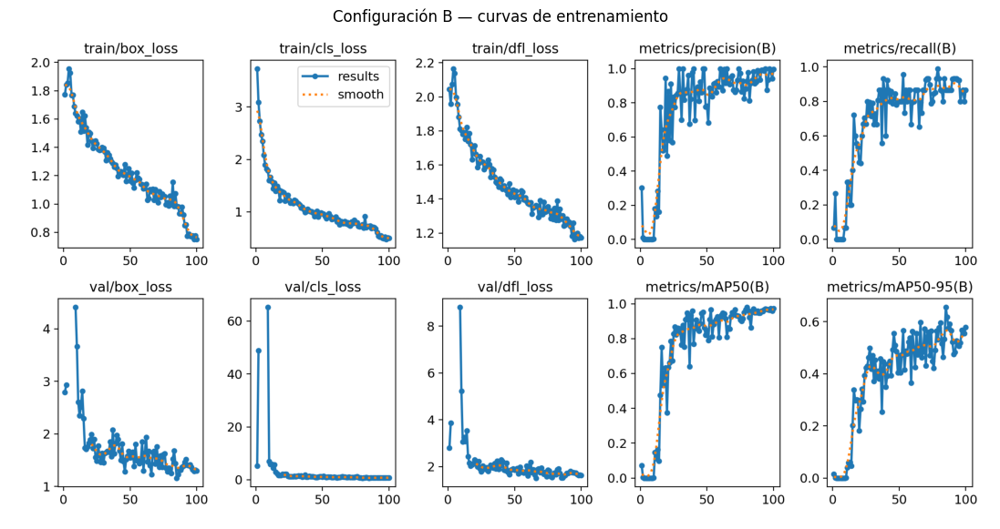

In [23]:
img = mpimg.imread(RUTA_B / "results.png")
plt.figure(figsize=(14, 7)); plt.imshow(img); plt.axis("off")
plt.title("Configuración B — curvas de entrenamiento"); plt.show()

In [24]:
# Mismo resumen numérico que para A
df_B = pd.read_csv(RUTA_B / "results.csv")
df_B.columns = [c.strip() for c in df_B.columns]
display(df_B[cols].iloc[[0, 9, 24, 49, 74, 89, 99]].round(3))

for p in ["box", "cls", "dfl"]:
    ep_min = int(df_B.loc[df_B[f"val/{p}_loss"].idxmin(), "epoch"])
    print(f"val/{p}_loss: mínimo en la época {ep_min} "
          f"({df_B[f'val/{p}_loss'].min():.3f}) | en la época 100: {df_B[f'val/{p}_loss'].iloc[-1]:.3f}")

,epoch,train/box_loss,val/box_loss,train/cls_loss,val/cls_loss,train/dfl_loss,val/dfl_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,1.774,2.795,3.732,5.252,2.044,2.794,0.073,0.015
9,10,1.621,3.663,1.596,6.906,1.803,5.230,0.001,0.000
24,25,1.426,1.486,1.220,1.270,1.623,1.784,0.828,0.424
49,50,1.162,1.549,0.964,1.097,1.412,1.852,0.846,0.470
74,75,1.054,1.611,0.789,1.039,1.356,1.853,0.908,0.448
89,90,0.924,1.390,0.676,0.771,1.270,1.726,0.947,0.521
99,100,0.751,1.299,0.494,0.724,1.174,1.638,0.974,0.578


val/box_loss: mínimo en la época 85 (1.159) | en la época 100: 1.299
val/cls_loss: mínimo en la época 80 (0.656) | en la época 100: 0.724
val/dfl_loss: mínimo en la época 66 (1.515) | en la época 100: 1.638


**Comentario de B**

- **Converge**, con un arranque inestable parecido al de A: en las primeras épocas la pérdida de validación aparece como `nan`.
- **Sin overfitting claro**, pero la brecha train/val es mayor que en A (box_loss 0.75 contra 1.30 al final).
- **El mAP@50-95 oscila mucho:** 0.655 en su mejor época y 0.578 en la última. Costo: ≈ 6.3 min y un archivo 3.5 veces más pesado.

### 3.3 Comparación A vs. B

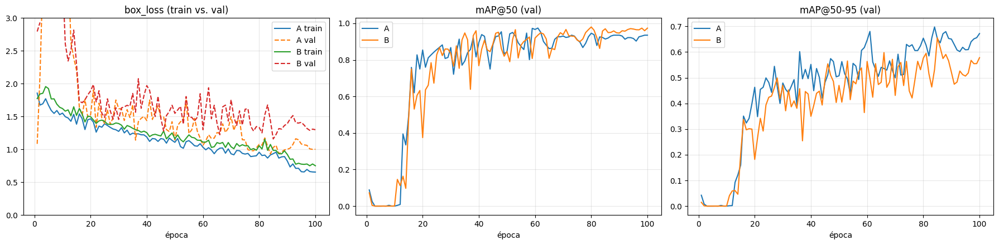

In [25]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.5))

# Pérdida de recuadro: train (línea llena) contra val (línea punteada)
ejes[0].plot(df_A["epoch"], df_A["train/box_loss"], label="A train")
ejes[0].plot(df_A["epoch"], df_A["val/box_loss"], "--", label="A val")
ejes[0].plot(df_B["epoch"], df_B["train/box_loss"], label="B train")
ejes[0].plot(df_B["epoch"], df_B["val/box_loss"], "--", label="B val")
ejes[0].set_ylim(0, 3)   # las primeras épocas tienen picos muy altos de val/box_loss
ejes[0].set_title("box_loss (train vs. val)")

# Métricas sobre validación
ejes[1].plot(df_A["epoch"], df_A["metrics/mAP50(B)"], label="A")
ejes[1].plot(df_B["epoch"], df_B["metrics/mAP50(B)"], label="B")
ejes[1].set_title("mAP@50 (val)")
ejes[2].plot(df_A["epoch"], df_A["metrics/mAP50-95(B)"], label="A")
ejes[2].plot(df_B["epoch"], df_B["metrics/mAP50-95(B)"], label="B")
ejes[2].set_title("mAP@50-95 (val)")

for eje in ejes:
    eje.set_xlabel("época"); eje.legend(); eje.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Las dos convergen y ninguna sobreajusta. B encuentra las gorras algo mejor (mAP@50) pero ajusta peor las cajas (mAP@50-95), y cuesta más. Con 45 fotos de entrenamiento, el modelo más grande no tiene con qué aprovechar su capacidad extra.

## 4. Fase 4 — Evaluación e inferencia

### 4.1 Métricas sobre validación

Evaluamos el `best.pt` de cada configuración. **Criterio:** gana la de mayor mAP@50-95, salvo que la diferencia sea menor a 0.02; en ese caso gana la más barata.

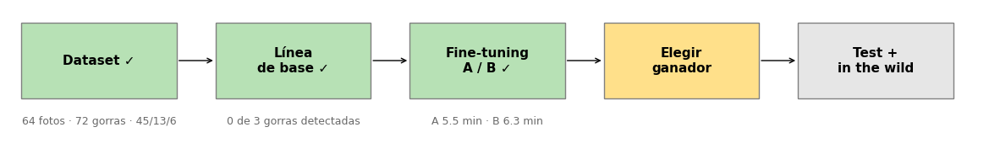

In [26]:
resultados_etapas["Fine-tuning A/B"] = f"A {TIEMPO_A_MIN:.1f} min · B {TIEMPO_B_MIN:.1f} min"
mostrar_progreso("Elegir ganador")

In [27]:
BEST_A = RUTA_A / "weights" / "best.pt"
BEST_B = RUTA_B / "weights" / "best.pt"

def evaluar(ruta_best, nombre):
    m = YOLO(ruta_best).val(data=DATA_YAML, split="val", project=RUNS, name=nombre, exist_ok=True)
    return [m.box.mp, m.box.mr, m.box.map50, m.box.map]   # precision, recall, mAP@50, mAP@50-95

met_A = evaluar(BEST_A, "val_A")
met_B = evaluar(BEST_B, "val_B")

tabla = pd.DataFrame(
    [met_A + [TIEMPO_A_MIN], met_B + [TIEMPO_B_MIN]],
    columns=["Precision", "Recall", "mAP@50", "mAP@50-95", "Tiempo de entrenamiento (min)"],
    index=["A — yolo11n", "B — yolo11s"],
).round(3)
display(tabla)

Ultralytics 8.4.210  Python-3.13.7 torch-2.9.1+cpu CPU (AMD Ryzen 5 8500G w/ Radeon 740M Graphics)


YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 372.8±154.6 MB/s, size: 62.7 KB)


val: Scanning C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\dataset\valid\labels... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 1.9Kit/s 0.0s

val: New cache created: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\datos\dataset\valid\labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0it/s 0.5s

... (8 outputs left out)

                   all         13         15      0.982      0.867       0.97      0.655


Speed: 0.9ms preprocess, 65.2ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect\val_B


,Precision,Recall,mAP@50,mAP@50-95,Tiempo de entrenamiento (min)
A — yolo11n,0.987,0.867,0.923,0.698,5.486
B — yolo11s,0.982,0.867,0.970,0.655,6.297


In [28]:
# Aplicamos el criterio: B gana solo si supera a A en mAP@50-95 por más de 0.02
diferencia = tabla.loc["B — yolo11s", "mAP@50-95"] - tabla.loc["A — yolo11n", "mAP@50-95"]
if diferencia > 0.02:
    GANADOR = "B"
    BEST_GANADOR = BEST_B
    FILA_GANADOR = "B — yolo11s"
else:
    GANADOR = "A"
    BEST_GANADOR = BEST_A
    FILA_GANADOR = "A — yolo11n"

print(f"Diferencia de mAP@50-95 (B - A): {diferencia:+.3f}")
print("Modelo ganador: configuración", GANADOR, "->", BEST_GANADOR)

Diferencia de mAP@50-95 (B - A): -0.043
Modelo ganador: configuración A -> C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\modelos\A\weights\best.pt


**Ganador: A (`yolo11n`).** Mismo recall que B, igual precision y mejor mAP@50-95 (0.698 contra 0.655), con un cuarto del tamaño.

### 4.2 Inferencia sobre test

Las 6 fotos de test (7 gorras) no se usaron ni para entrenar ni para elegir el modelo. Cada predicción se compara con el recuadro real usando **IoU** (área en común / área total):

| Tipo | Regla |
|---|---|
| TP con buena caja | IoU ≥ 0.75 con una gorra real |
| Caja mal ajustada | IoU entre 0.3 y 0.75 |
| Falso positivo | IoU < 0.3 con todas las gorras reales |
| Falso negativo | Gorra real sin ninguna predicción |

> **Ojo con la precision:** `val()` informa la precision en el umbral de confianza que da el mejor resultado, mientras que acá predecimos con `CONF = 0.25`. Por eso en test aparecen falsos positivos aunque la precision de validación sea 0.987.

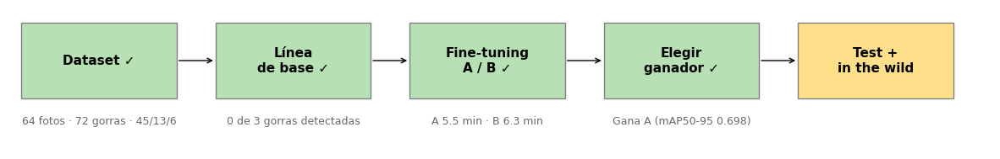

In [29]:
resultados_etapas["Elegir ganador"] = f"Gana {GANADOR} (mAP50-95 {tabla.loc[FILA_GANADOR, 'mAP@50-95']:.3f})"
mostrar_progreso("Test + in the wild")

In [30]:
# Recuadros reales de una foto, en píxeles: cada uno es [x1, y1, x2, y2] (esquina superior izquierda e inferior derecha)
def leer_recuadros_reales(ruta_imagen, ancho_img, alto_img):
    ruta_label = Path(ruta_imagen).parent.parent / 'labels' / (Path(ruta_imagen).stem + '.txt')
    cajas = []
    with open(ruta_label) as f:
        for linea in f.readlines():
            valores = linea.split()
            x, y = float(valores[1]) * ancho_img, float(valores[2]) * alto_img
            ancho, alto = float(valores[3]) * ancho_img, float(valores[4]) * alto_img
            cajas.append([x - ancho/2, y - alto/2, x + ancho/2, y + alto/2])
    return cajas

Cada foto de test se muestra dos veces: a la izquierda, con los recuadros reales; a la derecha, con lo que detectó el modelo.

0: 640x640 3 Gorras, 28.5ms
1: 640x640 1 Gorra, 28.5ms
2: 640x640 1 Gorra, 28.5ms
3: 640x640 2 Gorras, 28.5ms
4: 640x640 1 Gorra, 28.5ms
5: 640x640 3 Gorras, 28.5ms


Speed: 1.9ms preprocess, 28.5ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 640)


Results saved to C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect\test_ganador


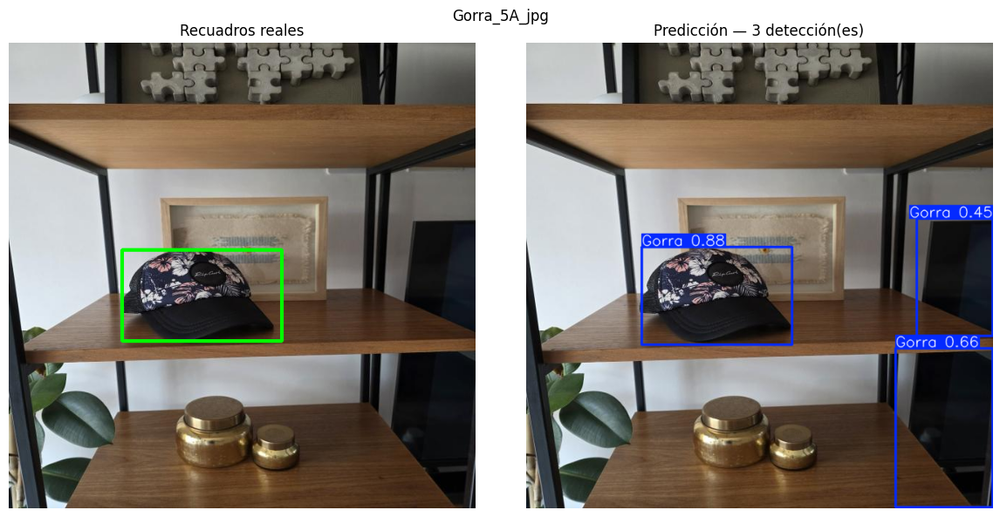

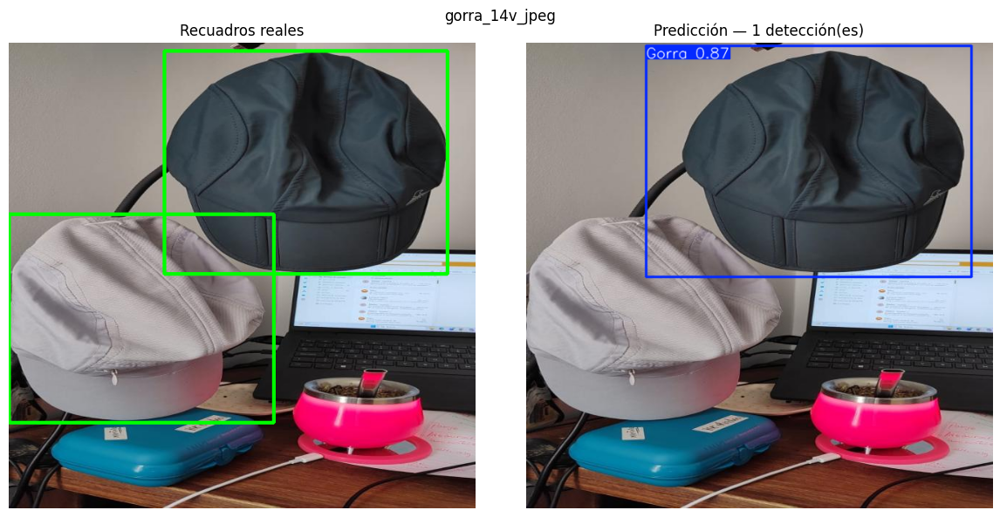

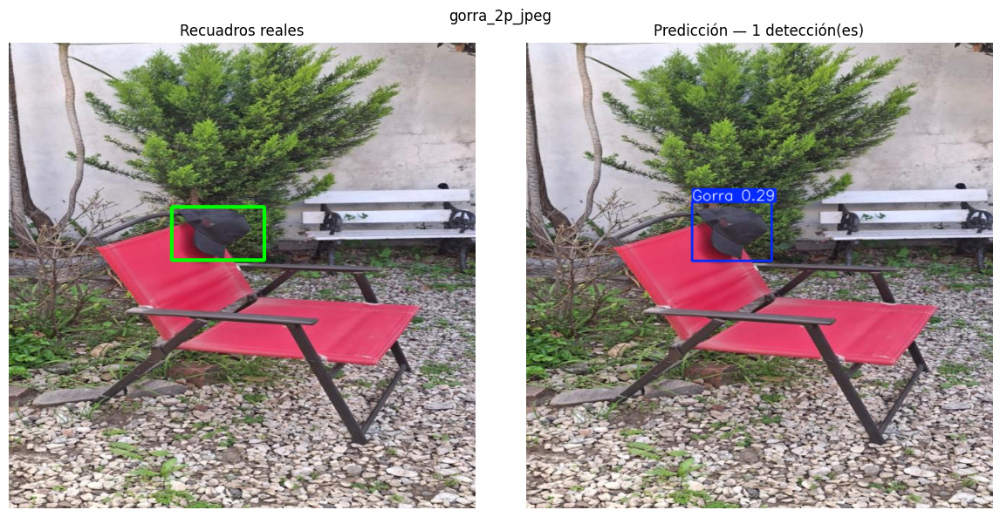

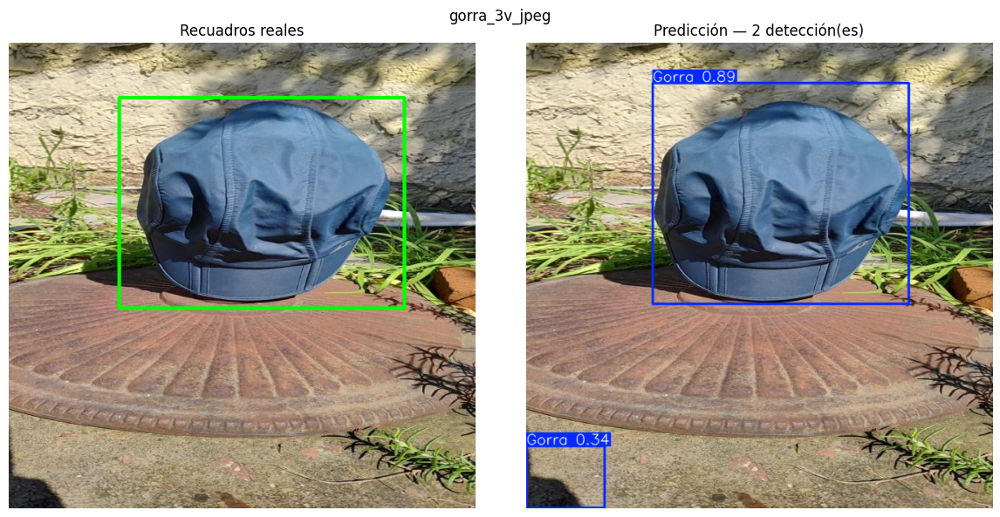

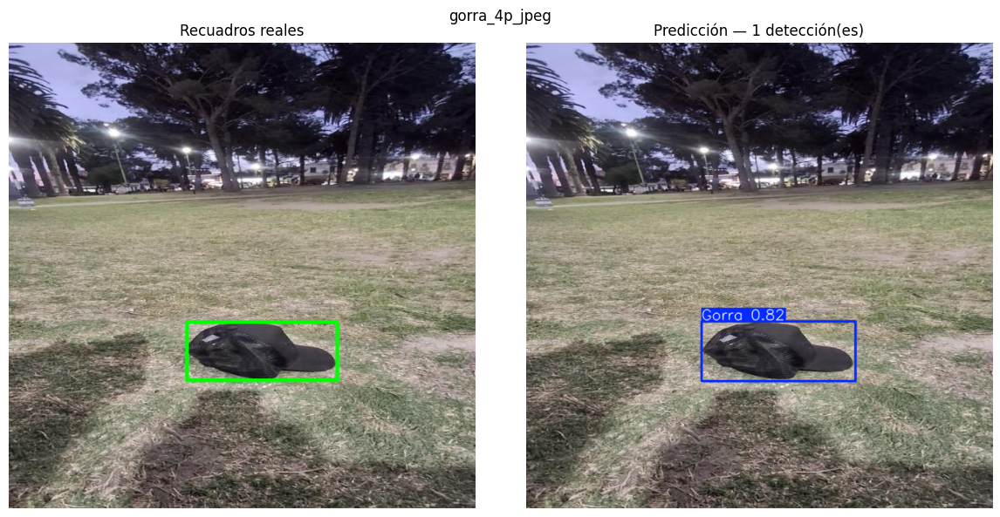

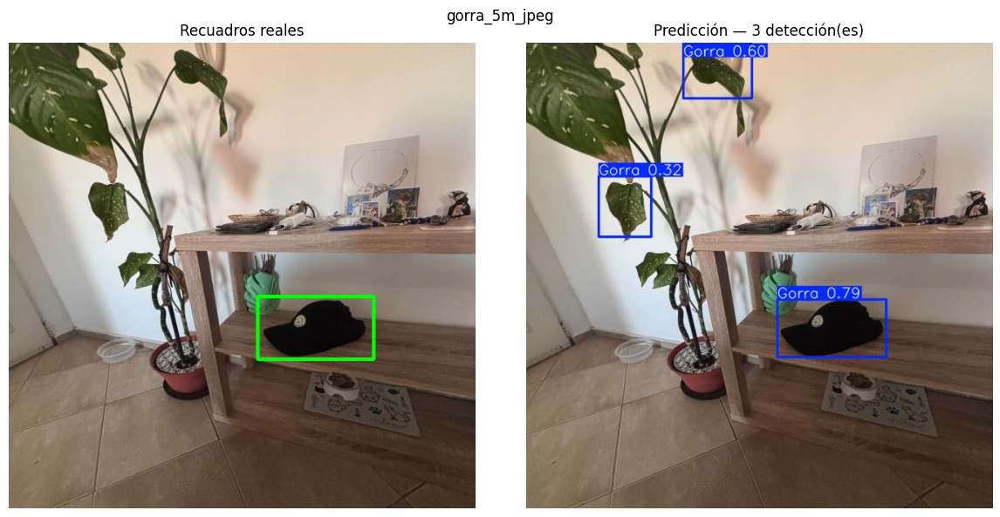

In [31]:
modelo_ganador = YOLO(BEST_GANADOR)

fotos_test = sorted(glob.glob(f'{data_dir}/test/images/*'))
pred_test = modelo_ganador.predict(source=fotos_test, conf=CONF, save=True,
                                   project=RUNS, name='test_ganador', exist_ok=True)

for ruta, r in zip(fotos_test, pred_test):
    # Izquierda: la foto con los recuadros reales en verde
    img = cv2.imread(ruta)
    alto_img, ancho_img = img.shape[:2]
    for x1, y1, x2, y2 in leer_recuadros_reales(ruta, ancho_img, alto_img):
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)

    fig, ejes = plt.subplots(1, 2, figsize=(12, 6))
    ejes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ejes[0].set_title('Recuadros reales')
    ejes[0].axis('off')

    # Derecha: lo que detectó el modelo, con su confianza
    ejes[1].imshow(r.plot()[..., ::-1])
    ejes[1].set_title(f'Predicción — {len(r.boxes)} detección(es)')
    ejes[1].axis('off')

    plt.suptitle(Path(ruta).name.split('.rf.')[0])
    plt.tight_layout()
    plt.show()

### 4.3 Análisis de errores

**IoU** mide cuánto se superponen dos cajas: vale 1 si son idénticas y 0 si no se tocan.

In [32]:
def iou(caja1, caja2):
    # Rectángulo en común entre las dos cajas
    x1 = max(caja1[0], caja2[0])
    y1 = max(caja1[1], caja2[1])
    x2 = min(caja1[2], caja2[2])
    y2 = min(caja1[3], caja2[3])
    interseccion = max(0, x2 - x1) * max(0, y2 - y1)

    # Área total que cubren las dos cajas juntas
    area1 = (caja1[2] - caja1[0]) * (caja1[3] - caja1[1])
    area2 = (caja2[2] - caja2[0]) * (caja2[3] - caja2[1])
    union = area1 + area2 - interseccion

    return interseccion / union if union > 0 else 0

Cada gorra real se empareja con una sola predicción, empezando por la de mayor confianza (Ultralytics ya devuelve las predicciones ordenadas así).

In [33]:
def clasificar_particion(particion, conf, fuente):
    fotos = sorted(glob.glob(f'{data_dir}/{particion}/images/*'))
    predicciones = modelo_ganador.predict(source=fotos, conf=conf, verbose=False)

    casos = []
    for ruta, r in zip(fotos, predicciones):
        alto_img, ancho_img = r.orig_shape
        reales = leer_recuadros_reales(ruta, ancho_img, alto_img)
        nombre = Path(ruta).name.split('.rf.')[0]
        usadas = []   # gorras reales que ya se emparejaron con una predicción

        for caja, confianza in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist()):
            # Buscamos la gorra real (todavía libre) que más se superpone con esta predicción
            mejor_iou, mejor_real = 0, None
            for j, real in enumerate(reales):
                valor = iou(caja, real)
                if j not in usadas and valor > mejor_iou:
                    mejor_iou, mejor_real = valor, j

            if mejor_iou >= 0.75:
                tipo = 'TP buena caja'
            elif mejor_iou >= 0.3:
                tipo = 'Caja mal ajustada'
            else:
                tipo = 'Falso positivo'

            caja_real = None
            if tipo != 'Falso positivo':
                usadas.append(mejor_real)
                caja_real = reales[mejor_real]
            casos.append({'fuente': fuente, 'foto': nombre, 'tipo': tipo, 'IoU': round(mejor_iou, 2),
                          'confianza': round(confianza, 2), 'ruta': ruta,
                          'caja_pred': caja, 'caja_real': caja_real})

        # Las gorras reales que ninguna predicción encontró son falsos negativos
        for j, real in enumerate(reales):
            if j not in usadas:
                casos.append({'fuente': fuente, 'foto': nombre, 'tipo': 'Falso negativo', 'IoU': 0,
                              'confianza': None, 'ruta': ruta, 'caja_pred': None, 'caja_real': real})
    return casos

Test tiene solo 7 gorras, así que sumamos validación para tener más ejemplos. Validación se usó para elegir el modelo: sus resultados son algo optimistas.

In [34]:
casos_df = pd.DataFrame(clasificar_particion('test', CONF, 'test') +
                        clasificar_particion('valid', CONF, 'valid'))

# Cantidad de casos de cada tipo, por partición
display(pd.crosstab(casos_df['tipo'], casos_df['fuente']))

# Detalle de todo lo que no fue un acierto con buena caja
columnas = ['fuente', 'foto', 'tipo', 'IoU', 'confianza']
display(casos_df[casos_df['tipo'] != 'TP buena caja'][columnas])

fuente,test,valid
tipo,,
Caja mal ajustada,0,2
Falso negativo,1,1
Falso positivo,5,2
TP buena caja,6,12


,fuente,foto,tipo,IoU,confianza
1,test,Gorra_5A_jpg,Falso positivo,0.00,0.66
2,test,Gorra_5A_jpg,Falso positivo,0.00,0.45
4,test,gorra_14v_jpeg,Falso negativo,0.00,NaN
7,test,gorra_3v_jpeg,Falso positivo,0.00,0.34
10,test,gorra_5m_jpeg,Falso positivo,0.00,0.60
11,test,gorra_5m_jpeg,Falso positivo,0.00,0.32
13,valid,gorra_10p_jpeg,Caja mal ajustada,0.69,0.85
15,valid,gorra_11p_jpeg,Falso positivo,0.00,0.39
18,valid,gorra_14m_png,Falso negativo,0.00,NaN
20,valid,gorra_17p_jpeg,Caja mal ajustada,0.56,0.84


Un ejemplo de cada tipo, priorizando test. Si falta algún tipo con `CONF`, se busca con `conf=0.1` y se aclara en el título.

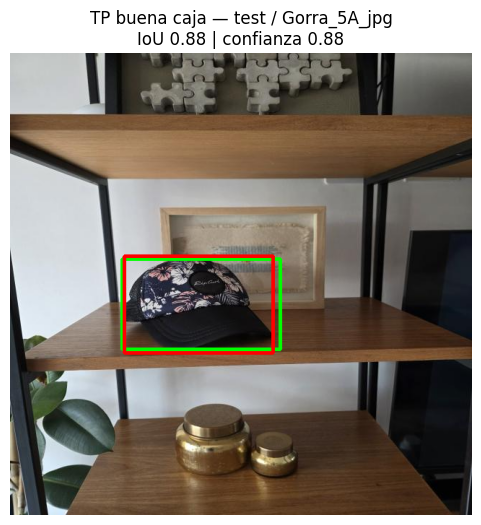

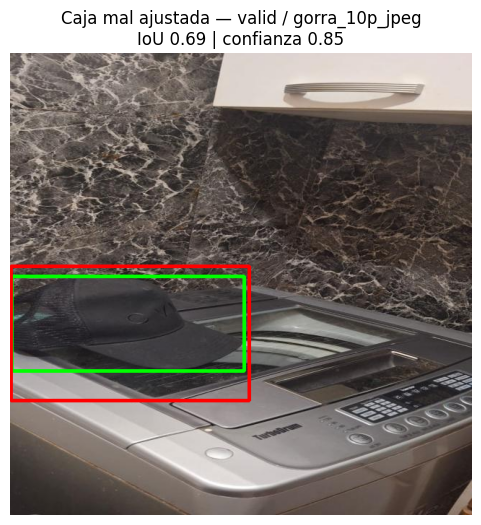

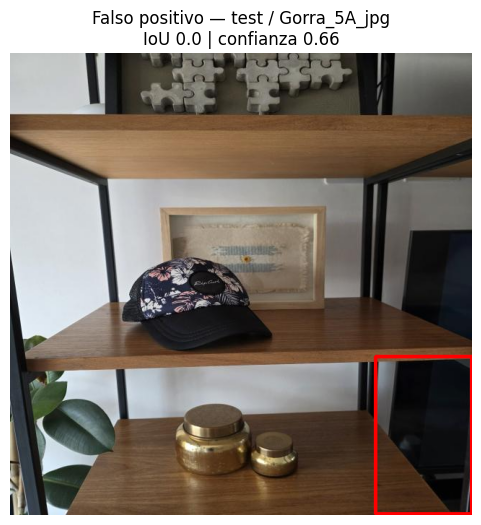

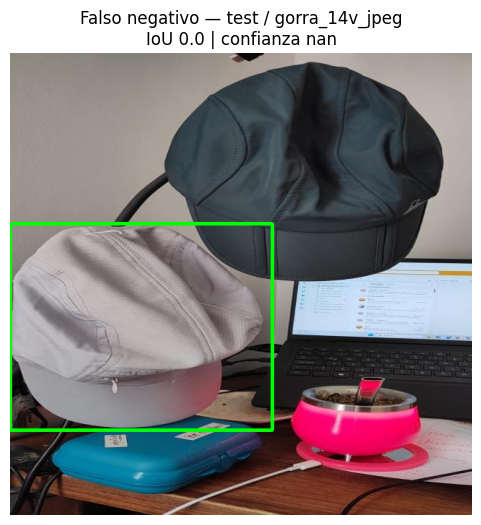

In [35]:
TIPOS = ['TP buena caja', 'Caja mal ajustada', 'Falso positivo', 'Falso negativo']

faltantes = [t for t in TIPOS if t not in casos_df['tipo'].values]
if faltantes:
    print(f'No aparecieron con conf={CONF}:', faltantes, '-> los buscamos con conf=0.1')
    casos_01 = pd.DataFrame(clasificar_particion('test', 0.1, 'test, conf=0.1') +
                            clasificar_particion('valid', 0.1, 'valid, conf=0.1'))
    casos_ejemplo = pd.concat([casos_df, casos_01])
else:
    casos_ejemplo = casos_df

for tipo in TIPOS:
    filas = casos_ejemplo[casos_ejemplo['tipo'] == tipo]
    if len(filas) == 0:
        print(f'No apareció ningún caso de "{tipo}", ni siquiera con conf=0.1.')
        continue
    caso = filas.iloc[0]   # el primero es de test si hay alguno en test

    # Recuadro real en verde y predicción en rojo
    img = cv2.imread(caso['ruta'])
    if caso['caja_real'] is not None:
        x1, y1, x2, y2 = [int(v) for v in caso['caja_real']]
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
    if caso['caja_pred'] is not None:
        x1, y1, x2, y2 = [int(v) for v in caso['caja_pred']]
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)

    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{tipo} — {caso['fuente']} / {caso['foto']}\nIoU {caso['IoU']} | confianza {caso['confianza']}")
    plt.axis('off')
    plt.show()

**Comentario** *(borrador para que Andrea revise)*

| | Test (7 gorras) | Valid (15 gorras) |
|---|---|---|
| TP con buena caja | 6 | 12 |
| Caja mal ajustada | 0 | 2 |
| Falso negativo | 1 | 1 |
| Falso positivo | 5 | 2 |

- **Encuentra casi todas las gorras de test** (6 de 7), con cajas bien ajustadas. La gorra chica de `gorra_2p` entró con 0.29, apenas sobre el umbral.
- **Falsos positivos sobre zonas oscuras:** el borde negro de la tele (`Gorra_5A`), una sombra (`gorra_3v`) y hojas oscuras (`gorra_5m`). Como la mayoría de las gorras del dataset son negras, el modelo asocia "mancha oscura" con gorra.
- **Falso negativo:** la gorra **gris clara** de `gorra_14v`, tapada en parte por una negra.
- **Caja mal ajustada:** `gorra_10p`, la gorra cortada por el borde. La caja se pasa hacia abajo (IoU 0.69).

### 4.4 Fotos "in the wild"

Tres fotos nuevas de exterior. Primero verificamos que no estén en el dataset: **si la celda no imprime nada, son nuevas.**

In [36]:
nombres = [Path(f).stem.lower() for f in fotos_wild]   # gorra_2d, gorra_5d, gorra_6d
for carpeta in ["train", "valid", "test"]:
    for f in os.listdir(os.path.join(data_dir, carpeta, "images")):
        if any(n in f.lower() for n in nombres):
            print(carpeta, f)

0: 640x384 (no detections), 23.9ms
1: 640x384 (no detections), 23.9ms
2: 640x384 1 Gorra, 23.9ms


Speed: 1.3ms preprocess, 23.9ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 384)


Results saved to C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\detect\in_the_wild


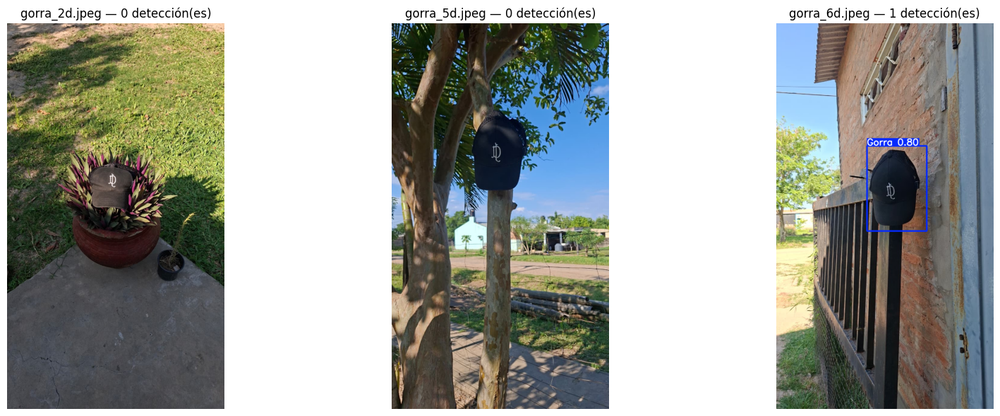

In [37]:
pred_wild = modelo_ganador.predict(source=fotos_wild, conf=CONF, save=True,
                                   project=RUNS, name="in_the_wild", exist_ok=True)

fig, ejes = plt.subplots(1, len(pred_wild), figsize=(6 * len(pred_wild), 6))
for eje, r in zip(ejes, pred_wild):
    eje.imshow(r.plot()[..., ::-1]); eje.axis("off")
    eje.set_title(f"{Path(r.path).name} — {len(r.boxes)} detección(es)")
plt.tight_layout(); plt.show()

**¿Influye el preprocesamiento?** Roboflow estiró las fotos de entrenamiento a 640x640: repetimos la inferencia con las fotos estiradas y con un umbral más bajo (0.05). Cada línea muestra las confianzas de las cajas detectadas.

In [38]:
CARPETA_640 = str(RAIZ / "runs" / "wild_640")
os.makedirs(CARPETA_640, exist_ok=True)
for f in fotos_wild:
    img = ImageOps.exif_transpose(Image.open(f)).convert("RGB").resize((640, 640))
    img.save(f"{CARPETA_640}/{Path(f).stem}.jpg")
fotos_640 = sorted(glob.glob(f"{CARPETA_640}/*"))

pruebas = [
    (f"original, conf {CONF}", fotos_wild, CONF),
    ("original, conf 0.05", fotos_wild, 0.05),
    (f"estirada 640x640, conf {CONF}", fotos_640, CONF),
    ("estirada 640x640, conf 0.05", fotos_640, 0.05),
]
for nombre, fuentes, conf in pruebas:
    print("==", nombre)
    for r in modelo_ganador.predict(source=fuentes, conf=conf, verbose=False):
        print("  ", Path(r.path).name, "->", [round(float(c), 2) for c in r.boxes.conf])

== original, conf 0.25
   gorra_2d.jpeg -> []
   gorra_5d.jpeg -> []
   gorra_6d.jpeg -> [0.8]
== original, conf 0.05
   gorra_2d.jpeg -> []
   gorra_5d.jpeg -> [0.11]
   gorra_6d.jpeg -> [0.8]
== estirada 640x640, conf 0.25


   gorra_2d.jpg -> [0.41]
   gorra_5d.jpg -> [0.62, 0.48]
   gorra_6d.jpg -> [0.85, 0.76]
== estirada 640x640, conf 0.05
   gorra_2d.jpg -> [0.41, 0.16]
   gorra_5d.jpg -> [0.62, 0.48, 0.12, 0.06]
   gorra_6d.jpg -> [0.85, 0.76]


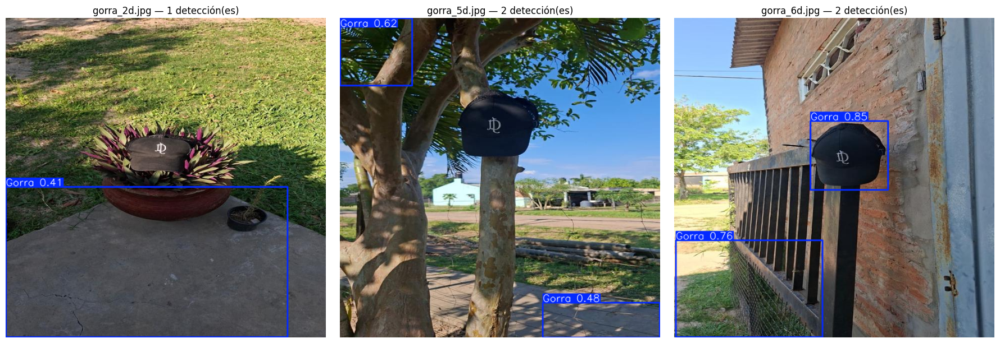

In [39]:
pred_640 = modelo_ganador.predict(source=fotos_640, conf=CONF, verbose=False)

fig, ejes = plt.subplots(1, len(pred_640), figsize=(6 * len(pred_640), 6))
for eje, r in zip(ejes, pred_640):
    eje.imshow(r.plot()[..., ::-1]); eje.axis("off")
    eje.set_title(f"{Path(r.path).name} — {len(r.boxes)} detección(es)")
plt.tight_layout(); plt.show()

| Foto | Original | Estirada a 640x640 |
|---|---|---|
| `gorra_2d` | Falso negativo | Sigue sin detectar la gorra, más un falso positivo (0.41) sobre el cemento |
| `gorra_5d` | Falso negativo | Sigue sin detectar la gorra, más 2 falsos positivos sobre una rama y el piso |
| `gorra_6d` | **Acierto** (0.80) | Acierto (0.85), más un falso positivo sobre el piso |

Acertó 1 de 3. Estirar las fotos como en el entrenamiento no lo arregla. Es la misma gorra negra, pero **colgada** y con sol fuerte, una situación que el dataset casi no tiene.

### 4.5 Guardado de resultados

Copia pesos, curvas, tablas y predicciones a `runs/entrega/`. Esa carpeta no se sube al repo: los pesos de la entrega ya están en `modelos/` y las tablas en `resultados/`.

In [40]:
RUTA_FINAL = RAIZ / "runs" / "entrega"
os.makedirs(RUTA_FINAL, exist_ok=True)

shutil.copy(BEST_A, RUTA_FINAL / "best_A.pt")
shutil.copy(BEST_B, RUTA_FINAL / "best_B.pt")
shutil.copy(RUTA_A / "results.png", RUTA_FINAL / "results_A.png")
shutil.copy(RUTA_B / "results.png", RUTA_FINAL / "results_B.png")
tabla.to_csv(RUTA_FINAL / "tabla_A_vs_B.csv")
casos_df[columnas].to_csv(RUTA_FINAL / "casos_test_valid.csv", index=False)
for carpeta in ["baseline", "test_ganador", "in_the_wild"]:
    shutil.copytree(f"{RUNS}/{carpeta}", RUTA_FINAL / carpeta, dirs_exist_ok=True)

print("Archivos copiados a:", RUTA_FINAL)
sorted(os.listdir(RUTA_FINAL))

Archivos copiados a: C:\Users\Equipo\Desktop\APRENDIZAJE AUTOMATICO II\TRABAJO PRACTICO 2\para github\runs\entrega


['baseline',
 'best_A.pt',
 'best_B.pt',
 'casos_test_valid.csv',
 'in_the_wild',
 'results_A.png',
 'results_B.png',
 'tabla_A_vs_B.csv',
 'test_ganador']

---
# Reporte final

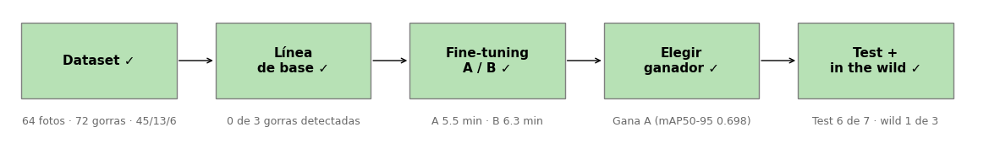

In [41]:
# Test: gorras encontradas (con buena caja o mal ajustada) sobre el total de gorras reales
test = casos_df[casos_df["fuente"] == "test"]
encontradas = test["tipo"].isin(["TP buena caja", "Caja mal ajustada"]).sum()
total_test = encontradas + (test["tipo"] == "Falso negativo").sum()
resultados_etapas["Test + in the wild"] = f"Test {encontradas} de {total_test} · wild 1 de 3"   # wild: tabla de la sección 4.4
mostrar_progreso("Fin")

## 1. Problema y dataset
Detectar **gorras con visera**, que no están en COCO. Son 64 fotos propias con 72 gorras, una sola clase, partición 45/13/6, cuatro aumentaciones solo en train, y 18 % de gorras chicas (detalle en la sección 1).

## 2. Línea de base
`yolo11n.pt` sin entrenar no detectó la gorra en ninguna de las 3 fotos: la ignoró o la llamó "person" (0.51).

## 3. Resultados de entrenamiento

| Config. | Precision | Recall | mAP@50 | mAP@50-95 | Tiempo | Tamaño |
|---|---|---|---|---|---|---|
| A — yolo11n | 0.987 | 0.867 | 0.923 | **0.698** | 5.5 min | 5.5 MB |
| B — yolo11s | 0.982 | 0.867 | **0.970** | 0.655 | 6.3 min | 19.2 MB |

**Gana A:** ajusta mejor las cajas, cuesta menos, y ninguna diferencia es concluyente con 13 fotos de validación. Las dos convergen sin overfitting claro (sección 3).

## 4. Resultados de inferencia
- **Test:** 6 de 7 gorras detectadas con buena caja, 1 perdida y 5 falsos positivos.
- **In the wild:** 1 de 3.

## 5. Análisis de errores
El detector funciona bien en fotos parecidas a las de entrenamiento y falla fuera de ellas. Los patrones que encontramos:

1. **Oscuro = gorra.** Los falsos positivos caen sobre zonas negras, y la gorra que se perdió es la clara.
2. **Pose.** Detecta gorras apoyadas; las colgadas in the wild no.
3. **El test es optimista.** Las mismas gorras aparecen en train y en test (la gorra floreada de `Gorra_5A` está en 8 fotos de train), porque la partición se hizo por foto y no por gorra. Además, test y valid vienen estiradas como train, y las fotos nuevas no.
4. **Sensibilidad al umbral.** Una gorra chica entró con 0.29 y los falsos positivos van de 0.32 a 0.66: un cambio chico de `CONF` cambia los resultados.
5. **Gorras cortadas por el borde** dan cajas mal ajustadas.

## 6. Conclusiones y trabajo futuro
El fine-tuning cumplió el objetivo: de no detectar nada a mAP@50 0.92 con 45 fotos y 5 minutos de entrenamiento. Con estos datos, el modelo chico rinde igual o mejor que el grande. El límite no es el modelo: son los **datos**.

**Qué haríamos distinto:**
- Más gorras distintas (claras, de colores), colgadas y en exterior.
- Fotos **sin** gorras con zonas oscuras, para bajar los falsos positivos.
- Separar train/valid/test **por gorra**, no por foto.
- Reemplazar el flip vertical por cambios de brillo y exposición.
- Mantener la proporción de las fotos (*letterbox*) en lugar de estirarlas.

**Con más tiempo:** volver a comparar A vs. B con más datos, probar `imgsz` mayor para las gorras chicas, y elegir el umbral de confianza con la curva precision-recall.